# Data Mining Project

### TASK: Classification by Naive Bayes
* #### Classification of at least 1 target variable of your choice:

  - You should discuss the choice of the attributes and identify the best parameter
    configurations (e.g. gain criterion for trees, best k for KNN etc.).
  - Discussion
  - Evaluate the quantitative performance of the algorithms w.r.t. confusion matrix, accuracy, precision, recall, F1, ROC curve
  - Discuss some insight (e.g. try to interpret the tree(s))
  - Which is the best algorithm? Best can be studied w.r.t. the performance evaluation or other preferred point of view;

### Informazioni Generali
* **Corso:** Data Mining
* **Università:** Università di Pisa
* **Anno Accademico:** 2024/2025

### Autore
* **Studente:** Giuseppe Muschetta

### Dataset Utilizzato
* **Nome:** IMDb Dataset (Data Matrix)
* **Descrizione:** Dataset consisting of 21909 points in 23 dimensions

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Global style setting for Seaborn and matplotlib plots
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",  # rocket, mako, crest, vlag, flare
    font="sans-serif",
    font_scale=1.1
)

# Other palette examples:
# dark mode: icefire, rocket, mako, crest, vlag, flare
# white theme: viridis, magma, plasma, inferno, cividis,

# Ottimizzazione dei caratteri (solo se vuoi)
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'lightgray'
plt.rcParams['ytick.color'] = 'lightgray'
plt.rcParams['text.color'] = 'white'
plt.rcParams['figure.facecolor'] = '#111111'
plt.rcParams['axes.facecolor'] = '#111111'
plt.rcParams['savefig.facecolor'] = '#111111'

In [3]:
# Create Directory for Plots ---
# To keep our project organized, we'll save all generated plots to a specific
# directory. This code creates a 'plots' directory if it doesn't already exist.

plots_dir = 'plots_classification/naive_bayes/'

if not os.path.exists(plots_dir):
    os.makedirs(plots_dir, exist_ok=True)
    print(f"Directory {plots_dir} created successfully.")
else:
    print(f"Directory {plots_dir} already exists.")

# Load the dataset ---
# Load the dataset from the provided CSV file into a pandas DataFrame, which is
# the primary data structure we will use for our analysis.

# Define the file path
dataset_dir = 'dataset/'
dataset_train = 'train_prepared.csv'
dataset_test = 'test_prepared.csv'

# Load the data
try:
    df_train = pd.read_csv(dataset_dir + dataset_train)
    print(f"dataset '{dataset_train}' loaded successfully.")
    print(f"The dataset contains {df_train.shape[0]} rows and {df_train.shape[1]} columns.")
    df_test = pd.read_csv(dataset_dir + dataset_test)
    print(f"dataset '{dataset_test}' loaded successfully.")
    print(f"The dataset contains {df_test.shape[0]} rows and {df_test.shape[1]} columns.")
except FileNotFoundError:
    print(f"Error: The dataset in the dir '{dataset_dir}' was not found. Please check the file path.")
    exit(1)


Directory plots_classification/naive_bayes/ created successfully.
dataset 'train_prepared.csv' loaded successfully.
The dataset contains 15609 rows and 55 columns.
dataset 'test_prepared.csv' loaded successfully.
The dataset contains 5478 rows and 55 columns.


--- Class Distribution for 'rating' (3 Tiers) ---

Counts:
rating_encoded
Good       6851
Poor       4419
Average    4339
Name: count, dtype: int64

Percentages:
rating_encoded
Good       43.89 %
Poor       28.31 %
Average     27.8 %
Name: proportion, dtype: object


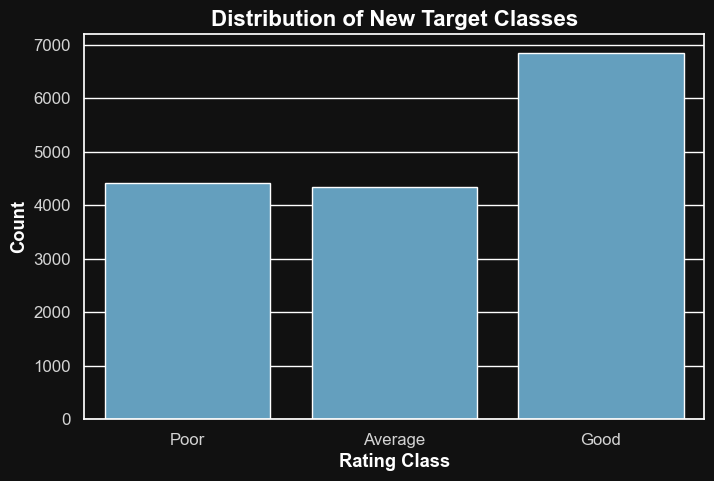

In [4]:
# --- Calculate Class Counts for the 3-Tier Rating System ---

def assign_rating_class(encoded_rating):
    """Groups the 10 encoded ratings into 3 final classes."""
    if encoded_rating <= 5:  # Original ratings up to 6.0
        return 'Poor'
    elif encoded_rating <= 6: # Original ratings from 6.1 to 7.0
        return 'Average'
    else:  # Original ratings from 7.1 to 10.0
        return 'Good'

# Create a temporary column to see the distribution
# We will make this permanent in the next step
temp_binned_col = df_train['rating_encoded'].apply(assign_rating_class)

# Calculate and print the counts and percentages for each class
class_distribution = temp_binned_col.value_counts()
class_percentages = temp_binned_col.value_counts(normalize=True) * 100

print("--- Class Distribution for 'rating' (3 Tiers) ---")
print("\nCounts:")
print(class_distribution)
print("\nPercentages:")
print(class_percentages.round(2).astype(str) + ' %')

# Plotting the distribution for a clear visual
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(x=class_distribution.index, y=class_distribution.values, order=['Poor', 'Average', 'Good'])
plt.title('Distribution of New Target Classes', fontsize=16, weight='bold')
plt.ylabel('Count')
plt.xlabel('Rating Class')
plt.show()

In [5]:
# --- 3.1. Target Variable and Feature Separation ---

# We will now make the creation of our target variable, 'rating_binned', permanent.
# The function defined previously will be applied to both the training and testing DataFrames.

def assign_rating_class(encoded_rating):
    """Groups the 10 encoded ratings into 3 final classes."""
    if encoded_rating <= 5:    # Corresponds to original ratings <= 6.0
        return 0 #'Poor'
    elif encoded_rating == 6:  # Corresponds to original ratings 6.1-7.0
        return 1 #'Average'
    else:                      # Corresponds to original ratings >= 7.1
        return 2 #'Good'

# Apply the function to create the target column
df_train['rating_binned'] = df_train['rating_encoded'].apply(assign_rating_class)
df_test['rating_binned'] = df_test['rating_encoded'].apply(assign_rating_class)

# Define the class names for later plotting
class_names = ['Poor', 'Average', 'Good']

print("Target variable 'rating_binned' created successfully.")
print("\nTrain set distribution:")
print(df_train['rating_binned'].value_counts())
print("\nTest set distribution:")
print(df_test['rating_binned'].value_counts())

Target variable 'rating_binned' created successfully.

Train set distribution:
rating_binned
2    6851
0    4419
1    4339
Name: count, dtype: int64

Test set distribution:
rating_binned
2    2414
0    1542
1    1522
Name: count, dtype: int64


In [6]:
# --- Separate Features (X) and Target (y) ---

# We define the feature matrix 'X' by dropping columns related to the target variable.
# The original 'averageRating' and the identifier 'tconst' were already removed
# during the preprocessing phase that created the '_prepared.csv' files.

# List of columns to drop to create the feature set
columns_to_drop = ['rating_encoded', 'rating_binned', 'originalTitle', 'endYear', 'startYear',
                   'runtimeMinutes', 'awardWins', 'numVotes', 'totalImages', 'totalVideos', 'totalCredits',
                   'criticReviewsTotal', 'awardNominationsExcludeWins', 'numRegions', 'userReviewsTotal']

# We add a check to ensure the columns exist before dropping, to prevent future errors
existing_columns_to_drop = [col for col in columns_to_drop if col in df_train.columns]

X_train = df_train.drop(columns=existing_columns_to_drop)
y_train = df_train['rating_binned']

X_test = df_test.drop(columns=existing_columns_to_drop)
y_test = df_test['rating_binned']

print("Features and target separated.")
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

# Let's check the features
print("\nFeatures being used for training:")
print(X_train.columns.tolist())

Features and target separated.
X_train shape: (15609, 41)
y_train shape: (15609,)
X_test shape: (5478, 41)
y_test shape: (5478,)

Features being used for training:
['titleType_movie', 'titleType_short', 'titleType_tvEpisode', 'titleType_tvMiniSeries', 'titleType_tvMovie', 'titleType_tvSeries', 'titleType_tvShort', 'titleType_tvSpecial', 'titleType_video', 'titleType_videoGame', 'genres_Drama', 'genres_Comedy', 'genres_Short', 'genres_Action', 'genres_Documentary', 'genres_Crime', 'genres_Adventure', 'genres_Animation', 'genres_Romance', 'genres_Family', 'countryOfOrigin_US', 'countryOfOrigin_GB', 'countryOfOrigin_JP', 'countryOfOrigin_FR', 'countryOfOrigin_CA', 'countryOfOrigin_IN', 'countryOfOrigin_DE', 'countryOfOrigin_IT', 'countryOfOrigin_ES', 'countryOfOrigin_AU', 'startYear_proc', 'awardWins_proc', 'numVotes_proc', 'totalImages_proc', 'totalVideos_proc', 'runtimeMinutes_proc', 'totalCredits_proc', 'criticReviewsTotal_proc', 'awardNominationsExcludeWins_proc', 'numRegions_proc', '

 #### Model 3: Naive Bayes

* Our third and final model is the Naive Bayes classifier.
* This model is based on Bayes' Theorem and operates under a "naive" assumption:
* that all features are conditionally independent of one another, given the class.
* While this is a strong and often unrealistic assumption,
* the algorithm is computationally efficient and can perform surprisingly well,
* especially in text classification and other high-dimensional problems.

 **Choosing the Right Naive Bayes:**
 There are several variants of Naive Bayes. Given our data, which is a mix of:
 - Standardized continuous features (`_proc` columns)
 - Binary features (0/1 from one-hot encoding and binarization)

 The `GaussianNB` classifier is the most suitable choice. It assumes that the likelihood of the continuous features for each class follows a Gaussian (normal) distribution. It can also handle our binary features without issue.

 **Steps:**
 1. Train a baseline `GaussianNB` classifier with default parameters.
 2. Use `GridSearchCV` to find the optimal value for the `var_smoothing` hyperparameter, which is a stability parameter that can help if feature variances are very low.
 3. Perform a thorough evaluation of the final, tuned model.

--- Training and Tuning Gaussian Naive Bayes ---
Fitting 5 folds for each of 10000 candidates, totalling 50000 fits

Best parameters found by GridSearchCV:
{'var_smoothing': 0.4540103009291865}

--- Evaluating Tuned Naive Bayes Model ---

Tuned Model Performance:
Accuracy: 0.5431

Classification Report:
              precision    recall  f1-score   support

        Poor       0.50      0.57      0.53      1542
     Average       0.38      0.08      0.14      1522
        Good       0.58      0.82      0.68      2414

    accuracy                           0.54      5478
   macro avg       0.49      0.49      0.45      5478
weighted avg       0.50      0.54      0.49      5478



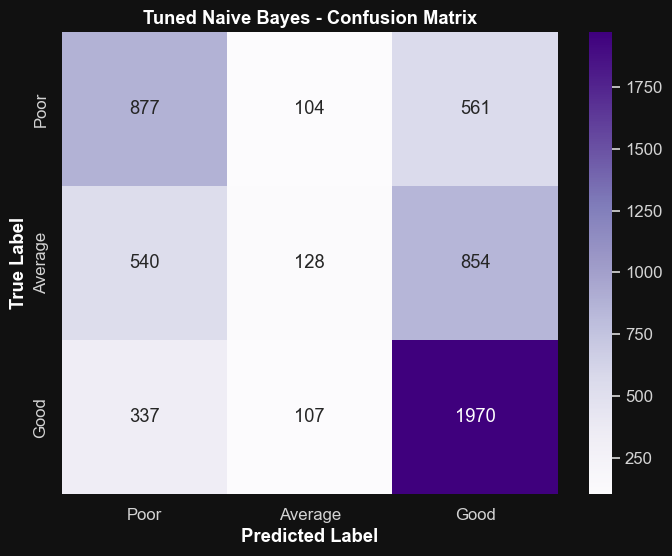


--- Generating ROC Curves for Tuned Naive Bayes ---


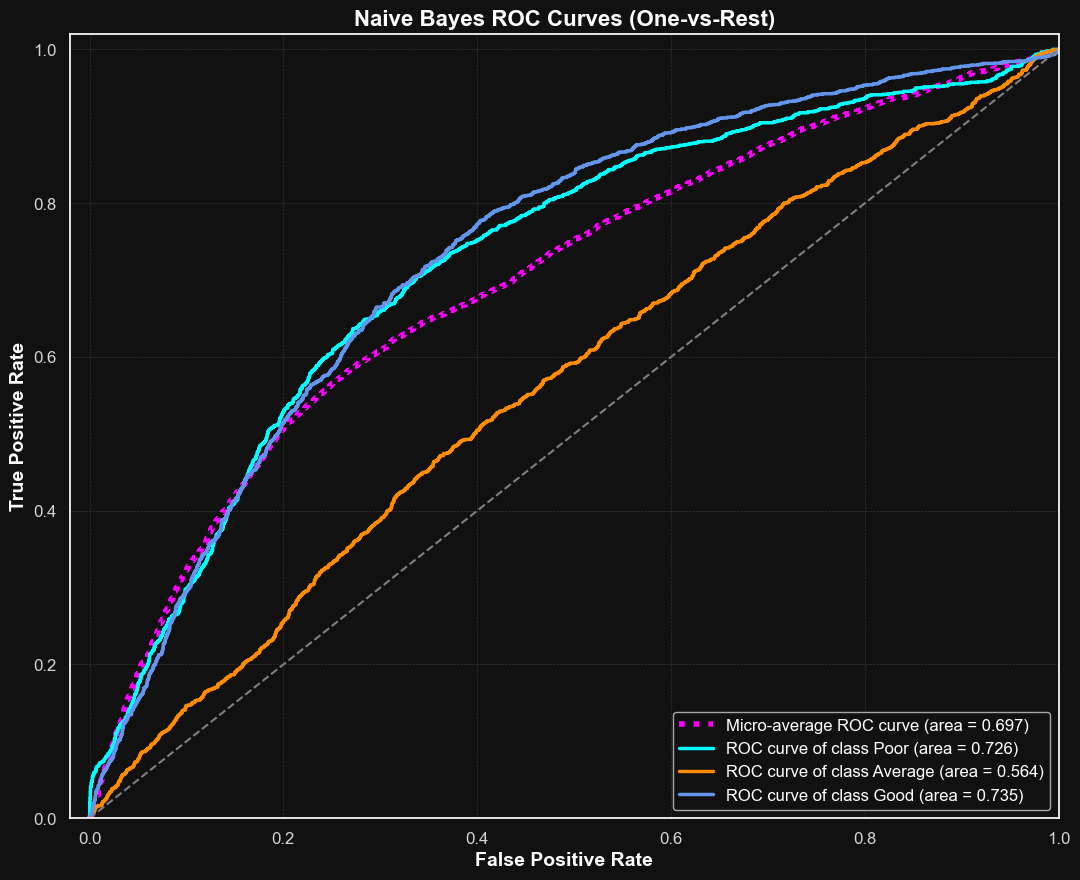

In [13]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# --- Training and Tuning Gaussian Naive Bayes ---
print("--- Training and Tuning Gaussian Naive Bayes ---")

# 1. Instantiate the model
gnb = GaussianNB()

# 2. Define the parameter grid for 'var_smoothing'
# var_smoothing is a stability parameter. We test a range of small values.
# np.logspace creates numbers spaced evenly on a log scale.
param_grid = {
    'var_smoothing': np.logspace(0,-9, num=10000)
}

# 3. Instantiate and run GridSearchCV
# This is usually very fast for Naive Bayes.
grid_search = GridSearchCV(estimator=gnb, param_grid=param_grid,
                           cv=5, n_jobs=-1, verbose=1, scoring='accuracy')

# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

# 4. Print the best parameters found
print("\nBest parameters found by GridSearchCV:")
print(grid_search.best_params_)

# 5. Get the best estimator
best_nb = grid_search.best_estimator_


# --- Final Model Evaluation (Tuned Naive Bayes) ---
print("\n--- Evaluating Tuned Naive Bayes Model ---")

# Make predictions with the best model found
y_pred_tuned = best_nb.predict(X_test)

# Evaluate the tuned model
print("\nTuned Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_tuned):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, target_names=class_names))

# Plotting the Confusion Matrix for the tuned model
plt.figure(figsize=(8, 6))
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.title('Tuned Naive Bayes - Confusion Matrix', weight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig(f'{plots_dir}nb_tuned_confusion_matrix.png', dpi=300)
plt.show()


# --- ROC Curve and AUC for Tuned Naive Bayes ---
print("\n--- Generating ROC Curves for Tuned Naive Bayes ---")

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle

# Binarize the output labels
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

# Get prediction probabilities
y_score = best_nb.predict_proba(X_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# --- Plotting with Enhanced Aesthetics ---
plt.figure(figsize=(11, 9))

# Plot micro-average ROC
plt.plot(fpr["micro"], tpr["micro"],
         label=f'Micro-average ROC curve (area = {roc_auc["micro"]:0.3f})',
         color='magenta', linestyle=':', linewidth=4)

# Plot ROC for each class
colors = cycle(['#00FFFF', '#FF8C00', '#6495ED']) # Aqua, DarkOrange, CornflowerBlue
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2.5,
             label=f'ROC curve of class {class_names[i]} (area = {roc_auc[i]:0.3f})')

# Plot the random classifier line
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')

# Customize the plot
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.02])
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.3)

# Labels, Title, and Legend
plt.xlabel('False Positive Rate', fontsize=14, weight='bold')
plt.ylabel('True Positive Rate', fontsize=14, weight='bold')
plt.title('Naive Bayes ROC Curves (One-vs-Rest)', fontsize=16, weight='bold')
plt.legend(loc="lower right", prop={'size': 12})
plt.tight_layout()
plt.savefig(f'{plots_dir}nb_roc_curves_final.png', dpi=300)
plt.show()

* --- Experimental Comparison: Bernoulli Naive Bayes ---

 To further understand the importance of choosing the correct model assumptions, we will now conduct an experiment with `BernoulliNB`. This classifier is designed for binary features. When applied to our dataset, it will internally treat our continuous `_proc` features as binary (e.g., values > 0 become 1, others become 0), which results in a significant loss of information.

 This comparison will serve two purposes:
 1. Quantify the performance difference between using the appropriate model (`GaussianNB`) and a theoretically less suitable one.
 2. Provide a deeper understanding of how Naive Bayes variants handle different types of data.

 We will tune the primary hyperparameter `alpha` (a smoothing parameter) using GridSearchCV.

--- Training and Tuning Bernoulli Naive Bayes ---
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best parameters found for BernoulliNB:
{'alpha': 0.001}

--- Evaluating Tuned Bernoulli Naive Bayes Model ---

Tuned BernoulliNB Model Performance:
Accuracy: 0.5265

Classification Report:
              precision    recall  f1-score   support

        Poor       0.48      0.60      0.54      1542
     Average       0.36      0.15      0.21      1522
        Good       0.59      0.71      0.65      2414

    accuracy                           0.53      5478
   macro avg       0.48      0.49      0.47      5478
weighted avg       0.50      0.53      0.50      5478



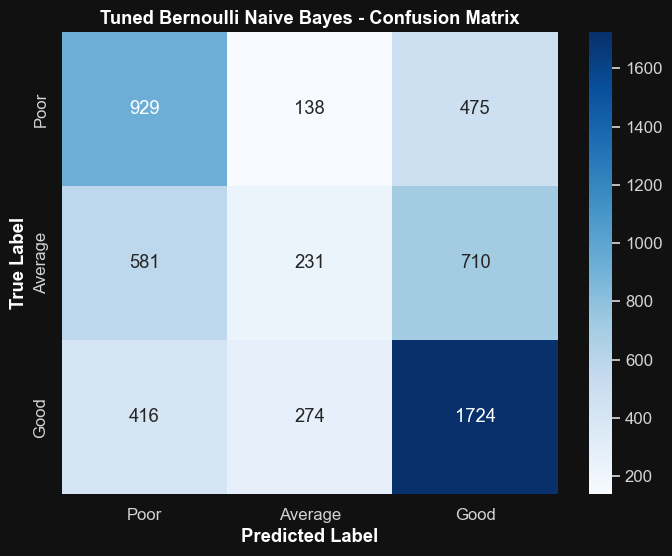

In [10]:
from sklearn.naive_bayes import BernoulliNB

# --- Training and Tuning Bernoulli Naive Bayes ---
print("--- Training and Tuning Bernoulli Naive Bayes ---")

# 1. Instantiate the model
bnb = BernoulliNB()

# 2. Define the parameter grid for 'alpha' (smoothing parameter)
# We test a range of values for alpha.
param_grid_bnb = {
    'alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
}

# 3. Instantiate and run GridSearchCV
grid_search_bnb = GridSearchCV(estimator=bnb, param_grid=param_grid_bnb,
                           cv=5, n_jobs=-1, verbose=1, scoring='accuracy')

# Fit GridSearchCV
grid_search_bnb.fit(X_train, y_train)

# 4. Print the best parameters found
print("\nBest parameters found for BernoulliNB:")
print(grid_search_bnb.best_params_)

# 5. Get the best estimator
best_bnb = grid_search_bnb.best_estimator_

# --- Final Model Evaluation (Tuned BernoulliNB) ---
print("\n--- Evaluating Tuned Bernoulli Naive Bayes Model ---")

# Make predictions
y_pred_bnb = best_bnb.predict(X_test)

# Evaluate the model
print("\nTuned BernoulliNB Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_bnb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_bnb, target_names=class_names))

# Plotting the Confusion Matrix
plt.figure(figsize=(8, 6))
cm_bnb = confusion_matrix(y_test, y_pred_bnb)
sns.heatmap(cm_bnb, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Tuned Bernoulli Naive Bayes - Confusion Matrix', weight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig(f'{plots_dir}bnb_tuned_confusion_matrix.png', dpi=300)
plt.show()